# Portfolio, grondstoffen & indicatoren met dagrendementen
We gaan, voor de statistische en grafische analyse van onze portfolio, de grondstoffen en de indicatoren, in plaats van met dagkoersen rekenen met dagrendementen. Daarvoor installeren we eerst de datareader & importeren de benodigde libraries:

In [ ]:
! pip install pandas-datareader==0.10.0
! pip install yfinance
! pip install --upgrade yfinance

import yfinance as yf
import pandas as pd
import pandas_datareader.data as web
import datetime as dt
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import date

#Clear output
from google.colab import output
output.clear()

# Aandelen, obligaties en crypto's
In dit deel van de Colab gaan we alle informatie over de portfolio verzamelen.

## Portfolio
We lezen eerst weer alle koersdata in:

In [ ]:
#yf.pdr_override()

start = dt.datetime(2018,5,1)
end = dt.datetime(2023,4,17)

apple = yf.download('AAPL', start, end).tz_localize(None) # Apple
shell = yf.download('SHEL', start, end).tz_localize(None) # Shell
ng = yf.download('NOC', start, end).tz_localize(None) # Northrop Grumman
tsm = yf.download('TSM', start, end).tz_localize(None) # Taiwan Semiconductor Manufacturing Company (TSMC)
rio = yf.download('RIO', start, end).tz_localize(None) # Rio Tinto Group
ge = yf.download('GE', start, end).tz_localize(None) # General Electric Company
gs = yf.download('GS', start, end).tz_localize(None) # The Goldman Sachs Group
bond = yf.download('BOND', start, end).tz_localize(None) # PIMCO Active Bond Exchange-Traded Fund
btc = yf.download('BTC-USD', start, end).tz_localize(None) # Bitcoin USD
xrp = yf.download('XRP-USD', start, end).tz_localize(None) # XRP USD

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


### Alternatieve manier voor het inlezen van de data

In [ ]:
# import data
def get_data(stocks, start, end):
    stockData = yf.download(stocks,start,end)
    stockData = stockData['Close']
    returns = stockData.pct_change()
    meanReturns = returns.mean()
    covMatrix = returns.cov()
    return stockData

stocklist = ['AAPL','SHEL','NOC','TSM','RIO','GE','GS','BOND','BTC-USD','XRP-USD']

endDate = dt.datetime.now()
startDate = endDate - dt.timedelta(days=1000)

portfolio_alt = get_data(stocklist, startDate, endDate)

[*********************100%***********************]  10 of 10 completed
<ipython-input-3-359118ab4d29>:5: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = stockData.pct_change()


In [ ]:
portfolio_alt

Ticker,AAPL,BOND,BTC-USD,GE,GS,NOC,RIO,SHEL,TSM,XRP-USD
Date,,,,,,,,,,
2022-03-08 00:00:00+00:00,157.440002,104.309998,38737.269531,54.918938,321.369995,449.209991,77.529999,52.939999,100.000000,0.720977
2022-03-09 00:00:00+00:00,162.949997,103.830002,41982.925781,56.850288,333.589996,449.920013,77.720001,51.709999,104.949997,0.767236
2022-03-10 00:00:00+00:00,158.520004,103.279999,39437.460938,56.900131,329.899994,444.609985,74.849998,51.689999,103.959999,0.737465
2022-03-11 00:00:00+00:00,154.729996,103.199997,38794.972656,57.491997,327.000000,436.299988,72.720001,50.930000,101.410004,0.802155
2022-03-12 00:00:00+00:00,NaN,NaN,38904.011719,NaN,NaN,NaN,NaN,NaN,NaN,0.786587
...,...,...,...,...,...,...,...,...,...,...
2024-11-28 00:00:00+00:00,NaN,NaN,95652.468750,NaN,NaN,NaN,NaN,NaN,NaN,1.541343
2024-11-29 00:00:00+00:00,237.330002,92.760002,97461.523438,182.160004,608.570007,489.649994,62.840000,64.739998,184.660004,1.796731
2024-11-30 00:00:00+00:00,NaN,NaN,96449.054688,NaN,NaN,NaN,NaN,NaN,NaN,1.944121


## Schonen van de data
Even weer alles samenvoegen, namen toevoegen en NaN's verwijderen:

In [ ]:
portfolio = pd.concat([apple.add_suffix("_Apple"), shell.add_suffix("_Shell"), ng.add_suffix("_Northrop"),tsm.add_suffix("_TSMC"), rio.add_suffix("_RioTinto"), ge.add_suffix("_GE"), gs.add_suffix("_GoldmanSachs"), bond.add_suffix("_Bond"), btc.add_suffix("_Bitcoin"), xrp.add_suffix("_Ripple")], axis=1)
portfolio_gefilterd = portfolio.loc[:, ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC","Close_RioTinto","Close_GE","Close_GoldmanSachs","Close_Bond","Close_Bitcoin","Close_Ripple"]]
portfolio_gefilterd.columns = ['Close_Apple', 'Close_Shell', 'Close_Northrop', 'Close_TSMC','Close_RioTinto','Close_GE','Close_GoldmanSachs','Close_Bond','Close_Bitcoin','Close_Ripple']
nans_gevuld = portfolio_gefilterd.ffill()
nans_gevuld

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
Date,,,,,,,,,,
2018-05-01,42.275002,69.050003,307.220001,38.930000,54.560001,67.333748,236.669998,102.639999,9119.009766,0.841407
2018-05-02,44.142502,69.180000,307.160004,37.750000,55.020000,67.956764,234.050003,102.589996,9235.919922,0.859094
2018-05-03,44.222500,69.610001,315.679993,38.099998,55.459999,66.758652,233.410004,102.580002,9743.860352,0.884466
2018-05-04,45.957500,69.839996,313.850006,38.590000,55.619999,67.573364,234.940002,102.709999,9700.759766,0.895442
2018-05-05,45.957500,69.839996,313.850006,38.590000,55.619999,67.573364,234.940002,102.709999,9858.150391,0.905103
...,...,...,...,...,...,...,...,...,...,...
2023-04-12,160.100006,61.380001,472.769989,86.870003,69.430000,75.099762,330.239990,93.110001,30139.052734,0.506115
2023-04-13,165.559998,62.070000,474.160004,87.050003,69.900002,75.259377,332.130005,92.970001,30399.066406,0.513292
2023-04-14,165.210007,62.060001,472.570007,87.199997,68.580002,76.169197,336.920013,92.620003,30485.699219,0.523993


## Dagrendementen
En nu gaan we de dagrendementen berekenen:

In [ ]:
return_portfolio = nans_gevuld.pct_change()
return_portfolio = return_portfolio.dropna()
return_portfolio

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
Date,,,,,,,,,,
2018-05-02,0.044175,0.001883,-0.000195,-0.030311,0.008431,0.009253,-0.011070,-0.000487,0.012820,0.021021
2018-05-03,0.001812,0.006216,0.027738,0.009271,0.007997,-0.017631,-0.002734,-0.000097,0.054996,0.029533
2018-05-04,0.039233,0.003304,-0.005797,0.012861,0.002885,0.012204,0.006555,0.001267,-0.004423,0.012410
2018-05-05,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.016225,0.010789
2018-05-06,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.020628,-0.037210
...,...,...,...,...,...,...,...,...,...,...
2023-04-12,-0.004353,0.009872,0.009610,-0.026558,-0.002586,0.002023,0.008767,0.003016,-0.003175,-0.022034
2023-04-13,0.034104,0.011241,0.002940,0.002072,0.006769,0.002125,0.005723,-0.001504,0.008627,0.014181
2023-04-14,-0.002114,-0.000161,-0.003353,0.001723,-0.018884,0.012089,0.014422,-0.003765,0.002850,0.020848


Conclusie?

## Statistiek
Statistische gegevens:

In [ ]:
return_portfolio.describe()

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
count,1811.000000,1811.000000,1811.000000,1811.000000,1811.000000,1811.000000,1811.000000,1811.000000,1811.000000,1811.000000
mean,0.000906,0.000136,0.000351,0.000615,0.000286,0.000326,0.000345,-0.000053,0.001335,0.001308
std,0.017494,0.019648,0.015023,0.018468,0.017861,0.022708,0.017319,0.002884,0.036359,0.056933
min,-0.128647,-0.171722,-0.101463,-0.140341,-0.098613,-0.151592,-0.127053,-0.041856,-0.371695,-0.423340
25%,-0.003517,-0.004738,-0.003610,-0.005136,-0.004024,-0.006977,-0.004826,-0.000623,-0.014387,-0.021580
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000871,-0.000664
75%,0.006918,0.005496,0.005039,0.006926,0.006637,0.006517,0.005563,0.000820,0.016637,0.019827
max,0.119808,0.196795,0.130012,0.126522,0.157880,0.147300,0.175803,0.019994,0.187465,0.560109


Conclusie?

## Grafieken
We maken een drietal grafieken:<br>
- overzicht van de dagrendementen gedurende de jaren<br>
- histogrammen<br>
- boxplots

### Dagrendement
Eerst een grafiek met daarin op de x-as de tijd, en op de y-as het dagrendement:

Text(0.5, 1.0, 'Dagrendementen')

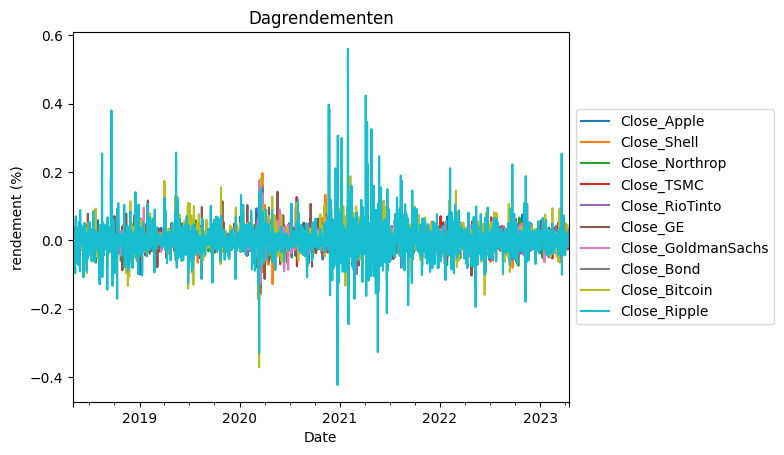

In [ ]:
return_portfolio.plot()
ax = plt.subplot(111)
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5)) # zet de legenda buiten de grafiek
plt.ylabel("rendement (%)")
plt.title("Dagrendementen")

Conclusie?

### Histogram

array([[<Axes: title={'center': 'Close_Apple'}>,
        <Axes: title={'center': 'Close_Shell'}>,
        <Axes: title={'center': 'Close_Northrop'}>,
        <Axes: title={'center': 'Close_TSMC'}>,
        <Axes: title={'center': 'Close_RioTinto'}>],
       [<Axes: title={'center': 'Close_GE'}>,
        <Axes: title={'center': 'Close_GoldmanSachs'}>,
        <Axes: title={'center': 'Close_Bond'}>,
        <Axes: title={'center': 'Close_Bitcoin'}>,
        <Axes: title={'center': 'Close_Ripple'}>]], dtype=object)

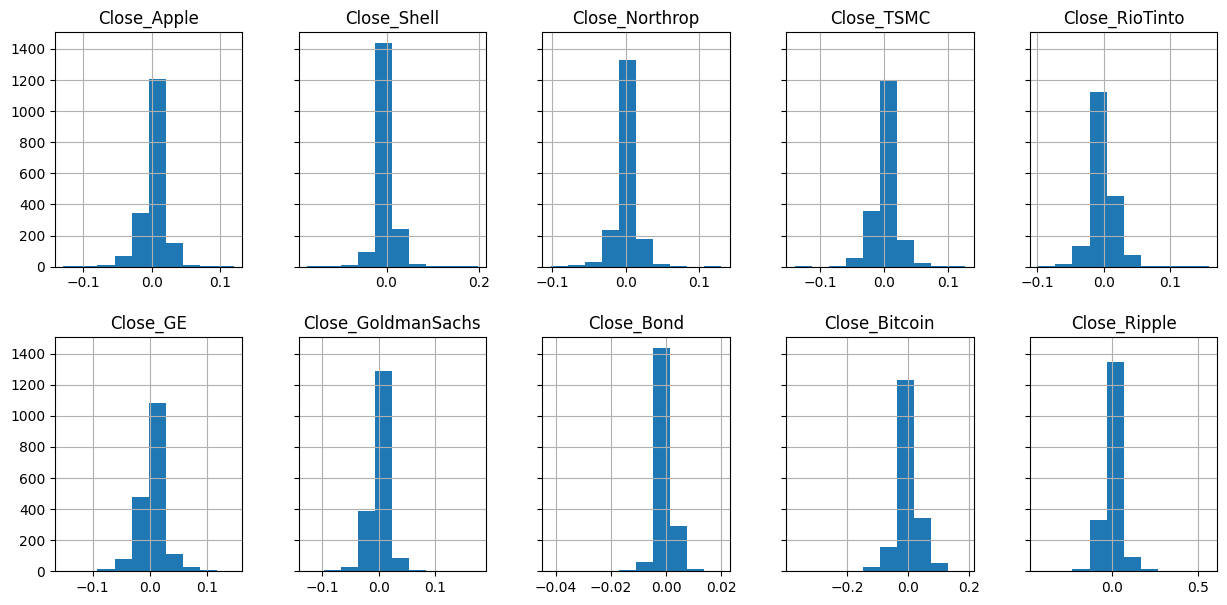

In [ ]:
return_portfolio.hist(layout=(2, 5), figsize=(15, 7), sharey=True)

Conclusie? Zijn de dagrendementen links-, normaal of rechtsscheef verdeeld? En wat betekent dat dan?

### Boxplot

<Axes: >

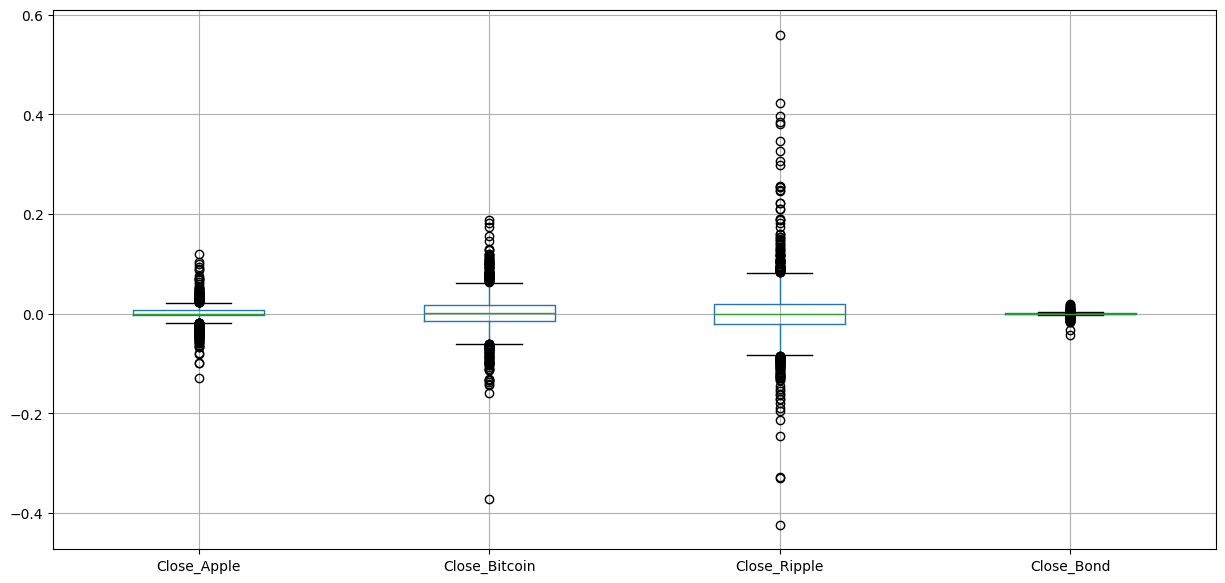

In [ ]:
return_portfolio.boxplot(column=["Close_Apple", "Close_Bitcoin","Close_Ripple","Close_Bond"], figsize=(15, 7))

Conclusie?

## Correlatiematrix

<Axes: >

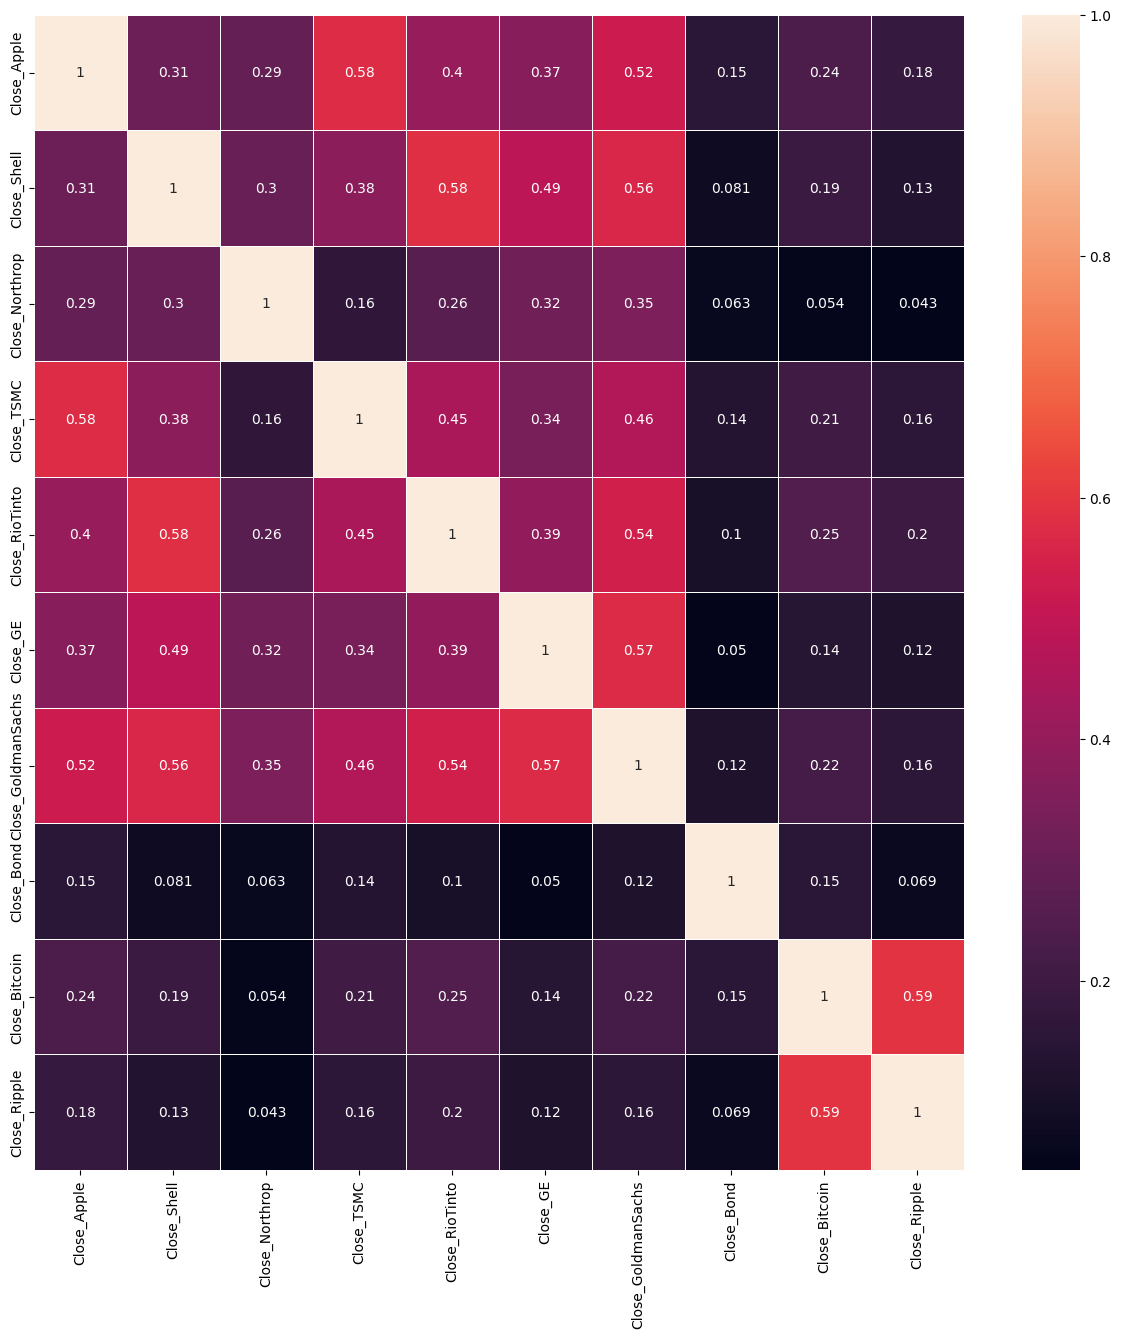

In [ ]:
fig, ax = plt.subplots(figsize=(15,15))         # Sample figsize in inches
sns.heatmap(return_portfolio.corr(),annot=True, linewidths=.5, ax=ax)

Conclusie? Welke verbanden zie je? Hoe sterk zijn deze?

# Grondstoffen en macro-economisch indicatoren
In dit deel van de Colab staat alle informatie over de grondstoffen en de macro-economische indicatoren.

## Grondstoffen en indicatoren
We gaan nu de grondstoffen en de macro-economische indicatoren inlezen:

In [ ]:
inflatie = web.get_data_fred('T10YIE', start, end) #inflatie
rente = web.get_data_fred('FEDFUNDS', start, end) #rente

graan = web.get_data_fred('PWHEAMTUSDM', start, end) #graan
hout = web.get_data_fred('WPU08', start, end) #hout
katoen = web.get_data_fred('PCOTTINDUSDM', start, end) #katoen
koffie = web.get_data_fred('WPU026301', start, end) #koffiebonen
rubber = web.get_data_fred('PRUBBUSDM', start, end) #rubber
vlees = web.get_data_fred('PBEEFUSDM', start, end) #vleesprijs
wol = web.get_data_fred('PWOOLFUSDM', start, end) #wol
zonnebloem = web.get_data_fred('PSUNOUSDM', start, end) #zonnebloemolie

gas = web.get_data_fred('GASREGW', start, end) #gas (US Regular All Formulations Gas Price)
kolen = web.get_data_fred('WPU058103', start, end) #kolen (Producer Price Index by Commodity: Fuels and Related Products and Power: Other Petroleum and Coal Products, Including Coke Oven Products, Not Elsewhere Classified)
oil = yf.download('CL=F', start, end).tz_localize(None) #olie
uranium = web.get_data_fred('PURANUSDM', start, end) #uranium

goud = yf.download('GC=F', start, end).tz_localize(None) #goud future
koper = web.get_data_fred('PCOPPUSDM', start, end) #koperprijs
palladium = yf.download('PA=F', start, end).tz_localize(None) #palladium
staal = web.get_data_fred('WPU101707', start, end) #staal (Producer Price Index by Commodity: Metals and Metal Products: Cold Rolled Steel Sheet and Strip )
zilver = yf.download('SI=F', start, end).tz_localize(None) #zilver future

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


## Schonen van de data

In [ ]:
indicatoren = pd.concat([rente, inflatie], axis=1)
indicatoren.columns = ["Rente", "Inflatie"]

In [ ]:
grondstoffen_1 = pd.concat([graan, koffie, vlees, gas, kolen], axis=1)
grondstoffen_1.columns = ["Graan", "Koffie", "Vlees", "Gas", "Kolen"]

In [ ]:
grondstoffen_2 = pd.concat([oil.add_suffix("_Olie"), goud.add_suffix("_Goud"), palladium.add_suffix("_Palladium")], axis = 1)
grondstoffen_2 = grondstoffen_2.loc[:, ["Close_Olie", "Close_Goud", "Close_Palladium"]]
grondstoffen_2.columns = ["Olie", "Goud", "Palladium"]

In [ ]:
grondstoffen_compleet = pd.concat([grondstoffen_1, grondstoffen_2], axis=1)
grondstoffen_compleet

,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-05-01,192.70383,194.2,188.0,NaN,595.4,67.250000,1303.800049,938.450012
2018-05-02,NaN,NaN,NaN,NaN,NaN,67.930000,1302.599976,962.349976
2018-05-03,NaN,NaN,NaN,NaN,NaN,68.430000,1310.699951,960.900024
2018-05-04,NaN,NaN,NaN,NaN,NaN,69.720001,1312.699951,959.450012
2018-05-07,NaN,NaN,NaN,2.845,NaN,70.730003,1312.199951,964.299988
...,...,...,...,...,...,...,...,...
2023-04-11,NaN,NaN,NaN,NaN,NaN,81.529999,2004.800049,1440.300049
2023-04-12,NaN,NaN,NaN,NaN,NaN,83.260002,2010.900024,1452.599976
2023-04-13,NaN,NaN,NaN,NaN,NaN,82.160004,2041.300049,1492.300049
2023-04-14,NaN,NaN,NaN,NaN,NaN,82.519997,2002.199951,1493.000000


In [ ]:
grondstoffen_gevuld = grondstoffen_compleet.ffill()
grondstoffen_gevuld = grondstoffen_gevuld.dropna()
grondstoffen_gevuld

,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-05-07,192.703830,194.200,188.000,2.845,595.400,70.730003,1312.199951,964.299988
2018-05-08,192.703830,194.200,188.000,2.845,595.400,69.059998,1312.000000,965.599976
2018-05-09,192.703830,194.200,188.000,2.845,595.400,71.139999,1311.300049,972.799988
2018-05-10,192.703830,194.200,188.000,2.845,595.400,71.360001,1320.800049,996.099976
2018-05-11,192.703830,194.200,188.000,2.845,595.400,70.699997,1319.000000,987.400024
...,...,...,...,...,...,...,...,...
2023-04-11,312.810824,240.495,248.375,3.596,859.822,81.529999,2004.800049,1440.300049
2023-04-12,312.810824,240.495,248.375,3.596,859.822,83.260002,2010.900024,1452.599976
2023-04-13,312.810824,240.495,248.375,3.596,859.822,82.160004,2041.300049,1492.300049
2023-04-14,312.810824,240.495,248.375,3.596,859.822,82.519997,2002.199951,1493.000000


## Dagrendementen

In [ ]:
return_grondstoffen = grondstoffen_gevuld.pct_change()
return_grondstoffen = return_grondstoffen.dropna()
return_grondstoffen

,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-05-08,0.0,0.0,0.0,0.000000,0.0,-0.023611,-0.000152,0.001348
2018-05-09,0.0,0.0,0.0,0.000000,0.0,0.030119,-0.000533,0.007457
2018-05-10,0.0,0.0,0.0,0.000000,0.0,0.003093,0.007245,0.023951
2018-05-11,0.0,0.0,0.0,0.000000,0.0,-0.009249,-0.001363,-0.008734
2018-05-14,0.0,0.0,0.0,0.009842,0.0,0.003678,-0.001895,0.010634
...,...,...,...,...,...,...,...,...
2023-04-11,0.0,0.0,0.0,0.000000,0.0,0.022448,0.007893,0.025636
2023-04-12,0.0,0.0,0.0,0.000000,0.0,0.021219,0.003043,0.008540
2023-04-13,0.0,0.0,0.0,0.000000,0.0,-0.013212,0.015118,0.027330
2023-04-14,0.0,0.0,0.0,0.000000,0.0,0.004382,-0.019155,0.000469


## Statistiek

In [ ]:
return_grondstoffen.describe()

,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
count,1289.000000,1289.000000,1289.000000,1289.000000,1289.000000,1289.000000,1289.000000,1289.000000
mean,0.000486,0.000170,0.000274,0.000238,0.000451,-0.002202,0.000374,0.000691
std,0.014837,0.002952,0.010917,0.009233,0.018017,0.098305,0.009626,0.026499
min,-0.190310,-0.018830,-0.151927,-0.056940,-0.281197,-3.059661,-0.049787,-0.208638
25%,0.000000,0.000000,0.000000,0.000000,0.000000,-0.011896,-0.003802,-0.011498
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.001304,0.000326,0.001290
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.014165,0.004973,0.013647
max,0.171974,0.084048,0.213948,0.136918,0.233814,0.376623,0.059477,0.253550


Conclusie?

## Grafieken
We maken een drietal grafieken:<br>
- overzicht van de dagrendementen gedurende de jaren<br>
- histogrammen<br>
- boxplots

### Dagrendement

Text(0.5, 1.0, 'Dagrendementen')

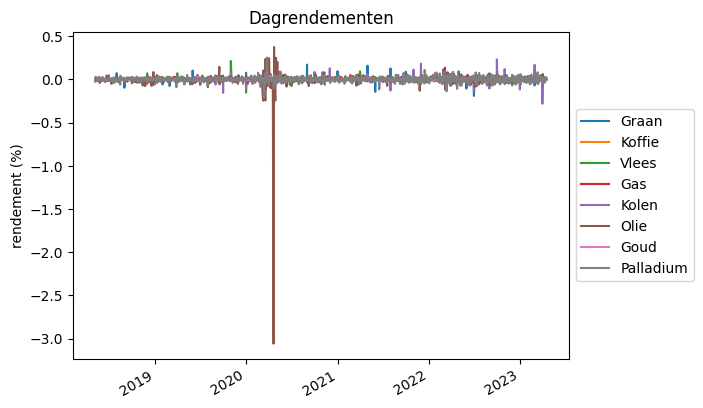

In [ ]:
return_grondstoffen.plot()
ax = plt.subplot(111)
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5)) # zet de legenda buiten de grafiek
plt.ylabel("rendement (%)")
plt.title("Dagrendementen")

Conclusie?

### Histogram

array([[<Axes: title={'center': 'Graan'}>,
        <Axes: title={'center': 'Koffie'}>,
        <Axes: title={'center': 'Vlees'}>,
        <Axes: title={'center': 'Gas'}>,
        <Axes: title={'center': 'Kolen'}>],
       [<Axes: title={'center': 'Olie'}>,
        <Axes: title={'center': 'Goud'}>,
        <Axes: title={'center': 'Palladium'}>, <Axes: >, <Axes: >]],
      dtype=object)

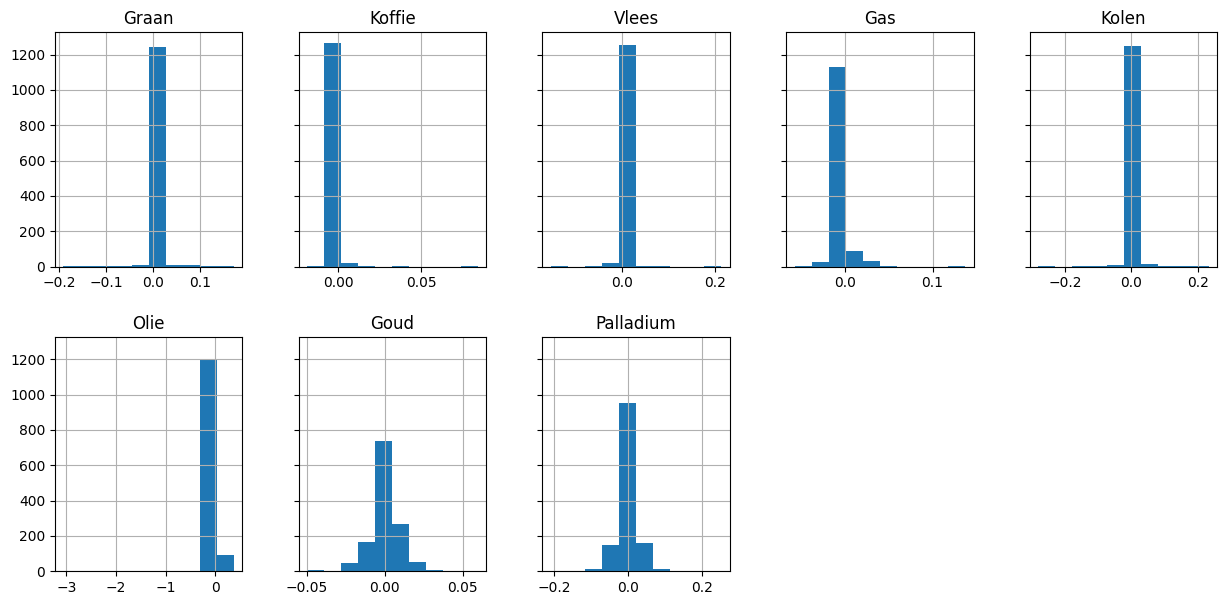

In [ ]:
return_grondstoffen.hist(layout=(2, 5), figsize=(15, 7), sharey=True)

Conclusie? Zijn de dagrendementen links-, normaal of rechtsscheef verdeeld? En wat betekent dat dan?

### Boxplot

<Axes: >

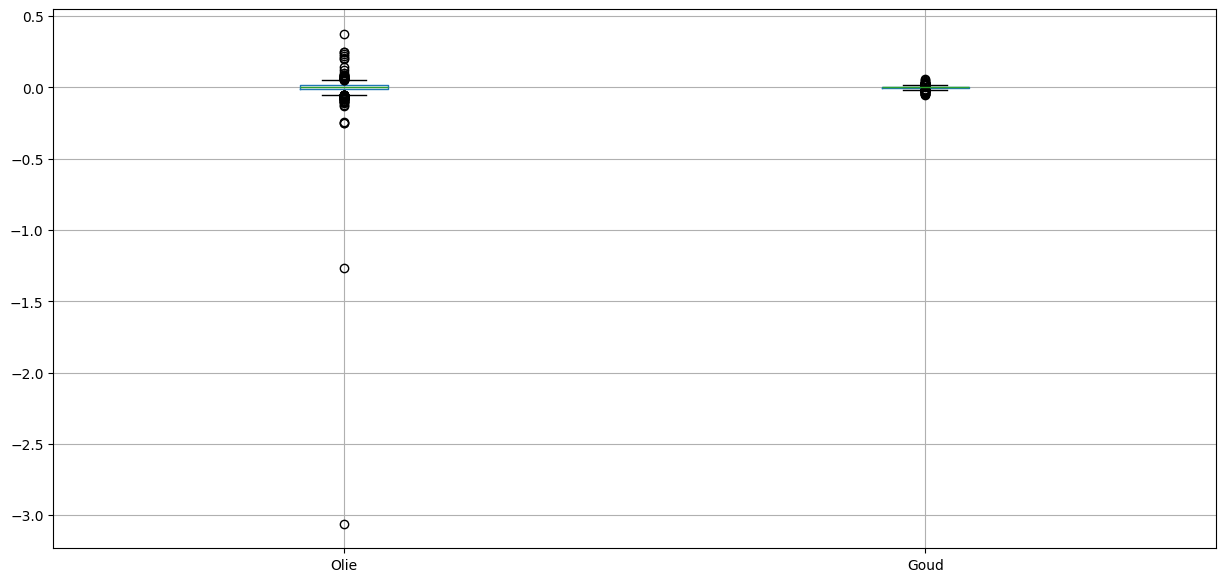

In [ ]:
return_grondstoffen.boxplot(column=["Olie","Goud"], figsize=(15, 7))

Conclusie

## Correlatiematrix

<Axes: >

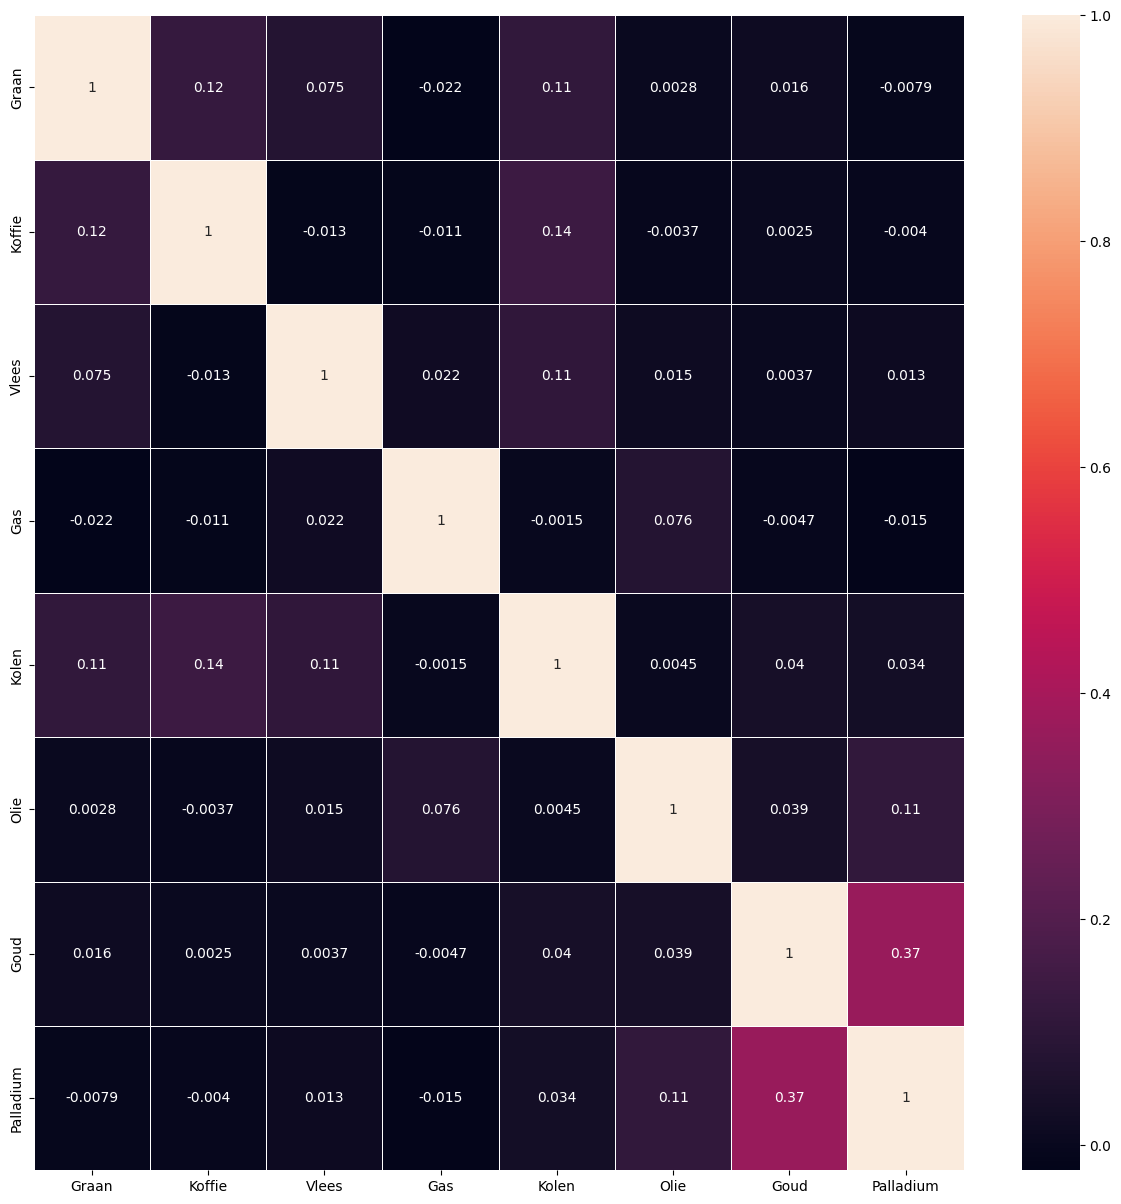

In [ ]:
fig, ax = plt.subplots(figsize=(15,15))         # Sample figsize in inches
sns.heatmap(return_grondstoffen.corr(),annot=True, linewidths=.5, ax=ax)

Conclusie? Welke verbanden zie je? Hoe sterk zijn deze?

# Portfolio, grondstoffen en indicatoren samen

In [ ]:
apt = pd.concat([return_portfolio, indicatoren, return_grondstoffen], axis=1)
apt_fill = apt.ffill()
apt_fill = apt_fill.dropna()
apt_fill

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple,Rente,Inflatie,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-05-08,0.004807,0.004302,0.038281,0.018986,-0.001262,0.014215,-0.000843,-0.001266,-0.014743,-0.022424,1.70,2.16,0.0,0.0,0.0,0.000000,0.0,-0.023611,-0.000152,0.001348
2018-05-09,0.007041,0.023990,-0.005102,0.004339,0.020754,0.024527,0.019958,-0.001462,0.009785,-0.014653,1.70,2.18,0.0,0.0,0.0,0.000000,0.0,0.030119,-0.000533,0.007457
2018-05-10,0.014304,-0.009483,-0.003602,0.010673,0.013967,0.004788,0.007074,0.001171,-0.030159,-0.054618,1.70,2.17,0.0,0.0,0.0,0.000000,0.0,0.003093,0.007245,0.023951
2018-05-11,-0.007630,0.013515,-0.003401,0.003520,0.000697,-0.006127,-0.002136,0.001268,-0.066614,-0.096657,1.70,2.15,0.0,0.0,0.0,0.000000,0.0,-0.009249,-0.001363,-0.008734
2018-05-12,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.007510,0.017209,1.70,2.15,0.0,0.0,0.0,0.000000,0.0,-0.009249,-0.001363,-0.008734
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-04-13,0.034104,0.011241,0.002940,0.002072,0.006769,0.002125,0.005723,-0.001504,0.008627,0.014181,4.83,2.29,0.0,0.0,0.0,0.000000,0.0,-0.013212,0.015118,0.027330
2023-04-14,-0.002114,-0.000161,-0.003353,0.001723,-0.018884,0.012089,0.014422,-0.003765,0.002850,0.020848,4.83,2.30,0.0,0.0,0.0,0.000000,0.0,0.004382,-0.019155,0.000469
2023-04-15,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.005485,-0.006773,4.83,2.30,0.0,0.0,0.0,0.000000,0.0,0.004382,-0.019155,0.000469
2023-04-16,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.000104,0.001822,4.83,2.30,0.0,0.0,0.0,0.000000,0.0,0.004382,-0.019155,0.000469


## Correlatiematrix

<Axes: >

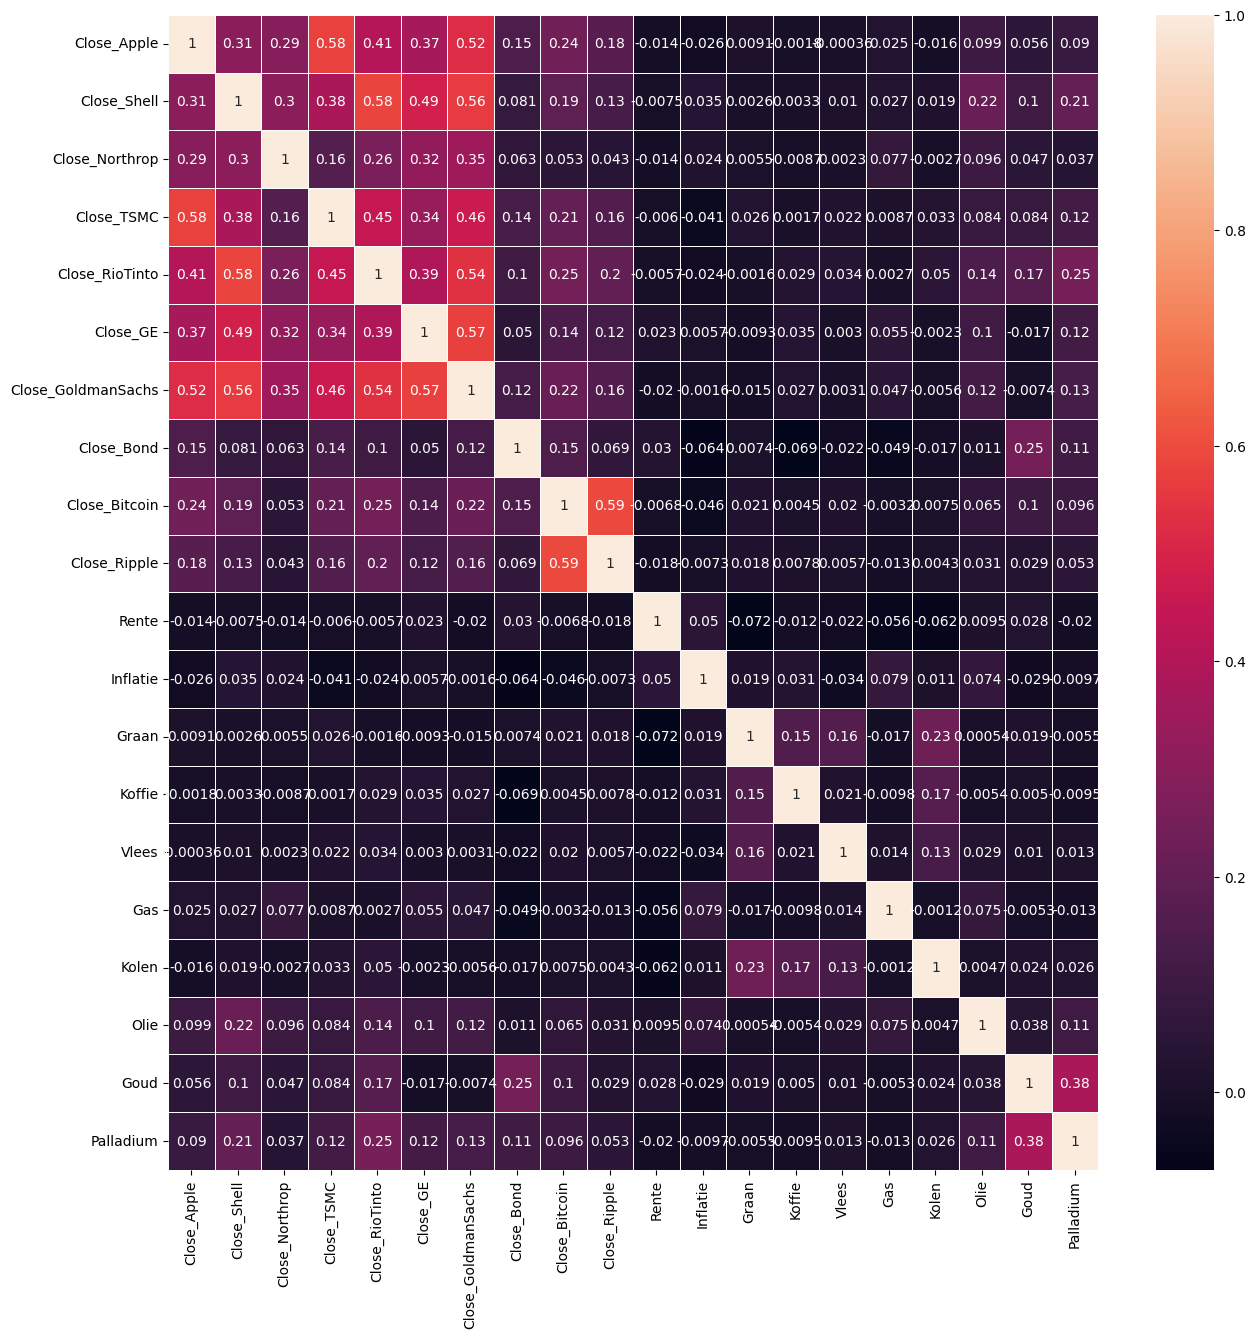

In [ ]:
fig, ax = plt.subplots(figsize=(15,15))         # Sample figsize in inches
sns.heatmap(apt_fill.corr(),annot=True, linewidths=.5, ax=ax)

Conclusie? Welke verbanden zie je? Hoe sterk zijn deze?